In [1]:
#%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (9.2 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
Using cached scipy-1.18.1-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (35.3 MB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Note: you may need to restart the kernel to use updated packages.


In [2]:
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

# 異常検知アルゴリズム：ポンプの故障を検知する

・システムインテグレーション(SI)を主な事業とするIT企業勤務  
・ポンプの故障検知に関する依頼  

・浄水場では、河川、湖、井戸などから原水を取り込んで場内の様々な処理を経て最終的に浄水場の外に送水を行うまでの水の移動に多くのポンプが使われている。  
・ポンプの故障がないかを日々点検して、メンテナンスすることが重要  

## ビジネス課題分析  

### 解決したい課題は何か？

【背景】  
・故障を予防するのは限界があり、月に１回程度ポンプが故障し、稼働停止する。  
・浄水場のサービスエリアで、一般家庭やビル、工場などの施設への水の供給が一時的に途絶えるという問題が起こる。  

　要望：この問題の解決のため、データを使って現状よりも高精度な故障の予防を実現したい

### 予測したい値は何か？

1. `故障が起こるよりも前に、故障を検知する必要がある。`  
何かしらの事象が起こる時点よりも前にその事象が起こるかどうかを予測したい、というのは時系列予測では一般的な構造である。
いつ時点でわかっているとよいかについては、なるべく早くわかっているとよい、というのは一般的に言えることだが、早く予測しようとするほど難しいタスクとなる。また、今回のケースでは、故障の予兆がどの時点で現れているかにもよるので、データ観察や分析を行ったうえで、現実的な期間を設けることが重要である。  

2. `データに予兆のラベルは付与されていない。`  
今回のタスクは「故障を事前に予測する」ことだが、別の言い方をすると「`現時点(予測時点)で故障の予兆が起こっているかどうかを予測する`」ということ。`故障の予兆が起こっているか`のラベルが付与されているケースもあるが、今回は付与されていないため、教師あり学習として取り組めない。  
この場合、そもそもデータ内に対象としている事象(今回は`故障の予兆`)が存在しているかどうかが不明瞭である点にも注意が必要である。また、教師ありとは異なり、定量的な評価を行う一般的な手法がないため、ゴール設定を明確化することが重要である。




### どんなアクションに使えるか？

故障を事前に検知できれば、検知結果を点検作業者に都度知らせ、必要に応じて実地点検を行うという運用に組み込むことが可能となる。   
その際に提供する情報次第で、作業者がより効率的に点検作業に当たることができ、故障の予防効果も高まる。  
また、通知の頻度と精度も重要であり、通知が多くてもその大半が誤報だと、作業者の負荷が高まるなどといった懸念が出てくる。  
そのため、頻度と精度のバランスは顧客とよく話し合い、調節する必要がある。

### 特徴量として何が使えるか？

今回は、`あるポンプに取り付けられたセンサーデータ`、および、`ポンプの状態を示すラベル`を用いて異常検知を行う。  

## データ分析、機械学習

### データ観察

In [3]:
import pandas as pd

df = pd.read_csv("sensor.csv")
df.shape

(22032, 20)

In [4]:
df.head()

,timestamp,s00,s01,s02,s03,s04,s05,s06,s07,s08,s09,s10,s11,s12,s13,s14,s15,s16,s17,machine_status
0,2018-04-01 00:00:00,2.454966,47.131073,75.898200,1.666368,420.09408,447.91395,164.16404,93.344712,42.057289,31.901041,74.687495,38.888888,62.615740,38.715276,166.98494,67.795142,242.27431,201.64930,NORMAL
1,2018-04-01 00:10:00,2.455064,48.315972,77.241510,1.680008,419.89171,456.04422,163.66479,89.701563,45.260414,32.343747,75.078122,41.637731,53.096062,39.409722,214.23612,73.119211,249.27664,199.79745,NORMAL
2,2018-04-01 00:20:00,2.452899,48.897568,76.463261,1.823943,419.96173,449.19264,167.25610,91.697104,45.208330,32.291665,67.265623,39.033564,50.000000,40.248843,206.65509,94.733809,244.44445,209.49074,NORMAL
3,2018-04-01 00:30:00,2.456441,48.559026,73.055601,1.760167,419.92536,443.67406,171.30731,87.932910,42.682289,34.270830,66.510415,36.660878,46.701389,40.277777,209.34606,92.563662,248.26389,222.51157,NORMAL
4,2018-04-01 00:40:00,2.453391,49.118921,74.300801,1.952894,420.20299,451.84222,170.76836,89.452807,43.229164,33.229163,68.307289,37.123841,45.341436,37.876157,210.32985,71.672455,227.02546,217.04283,NORMAL


・timestamp：10分刻みのデータ  
・s00～s17：センサーデータ  
・machine_status：時刻ごとのポンプの状態を示すラベル  

#### timestamp列
データ型を`datetime64`に変更することで、時刻間の演算ができるようになる。また、利便性のためにset_index()でインデックスに指定する。

In [5]:
df["timestamp"] = df["timestamp"].astype("datetime64[ns]")
# set_index：データとして扱っていた値を行として扱う
df = df.set_index("timestamp")
df.head()

,s00,s01,s02,s03,s04,s05,s06,s07,s08,s09,s10,s11,s12,s13,s14,s15,s16,s17,machine_status
timestamp,,,,,,,,,,,,,,,,,,,
2018-04-01 00:00:00,2.454966,47.131073,75.898200,1.666368,420.09408,447.91395,164.16404,93.344712,42.057289,31.901041,74.687495,38.888888,62.615740,38.715276,166.98494,67.795142,242.27431,201.64930,NORMAL
2018-04-01 00:10:00,2.455064,48.315972,77.241510,1.680008,419.89171,456.04422,163.66479,89.701563,45.260414,32.343747,75.078122,41.637731,53.096062,39.409722,214.23612,73.119211,249.27664,199.79745,NORMAL
2018-04-01 00:20:00,2.452899,48.897568,76.463261,1.823943,419.96173,449.19264,167.25610,91.697104,45.208330,32.291665,67.265623,39.033564,50.000000,40.248843,206.65509,94.733809,244.44445,209.49074,NORMAL
2018-04-01 00:30:00,2.456441,48.559026,73.055601,1.760167,419.92536,443.67406,171.30731,87.932910,42.682289,34.270830,66.510415,36.660878,46.701389,40.277777,209.34606,92.563662,248.26389,222.51157,NORMAL
2018-04-01 00:40:00,2.453391,49.118921,74.300801,1.952894,420.20299,451.84222,170.76836,89.452807,43.229164,33.229163,68.307289,37.123841,45.341436,37.876157,210.32985,71.672455,227.02546,217.04283,NORMAL


In [6]:
# timestamp列の概観
print(df.index.min())
print(df.index.max())
print(df.index.max() - df.index.min())
print(len(df.index.drop_duplicates()))

2018-04-01 00:00:00
2018-08-31 23:50:00
152 days 23:50:00
22032


上記より...  
・2018/4/1～2018/8/31までの５か月(153日)分のデータ  
・drop_duplicates()の結果が元のレコード数と一致するため、重複値を持たないことが分かる  
・153(日)×24(時間)×60(分)÷10(分)=22032とレコード数が一致していることが分かる  

#### machine_status列

In [7]:
df["machine_status"].value_counts(dropna=False)

machine_status
NORMAL        20578
RECOVERING     1447
BROKEN            7
Name: count, dtype: int64

NORMAL(正常)、RECOVERING(修理中)、BROKEN(故障)

In [8]:
# 各状態の持続期間を確認する  
def check_machine_status_transition(df: pd.DataFrame):
    def print_duration(current, last_changed_at, status):
        # 10s：10文字分のスペースを指定
        print(f"{current}:{status:10s} lasted{current - last_changed_at}")
    
    status = df["machine_status"].iloc[0] # 初期値として最初のステータスを覚えておく
    last_changed_at = df.index[0] # 初期値として最初の時刻を覚えておく
    # df.iterrows()：DataFrameを１行ずつ取り出す
    for i, rows in df.iterrows(): # i：インデックス(時刻)を順に取り出す、rows：データフレームの行を順番に取りだす
        if status != rows["machine_status"]: # もしstatus(初期値)と異なるステータスの行がヒットしたら以下に進む！
            print_duration(i, last_changed_at, status) # （今の時刻, 初期時刻, 初期ステータス）で計算
            last_changed_at = i # ここで初めてlast_changed_atが更新される
        status = rows["machine_status"] # ifの外に置くことで、statusの中には常に「直前」のステータス情報を入れておく
    print_duration(i, last_changed_at, status) # 最後にまた置くことで、一番最後のブロックの分も記録

In [9]:
check_machine_status_transition(df)

2018-04-12 21:50:00:NORMAL     lasted11 days 21:50:00
2018-04-12 22:00:00:BROKEN     lasted0 days 00:10:00
2018-04-13 13:40:00:RECOVERING lasted0 days 15:40:00
2018-04-18 00:30:00:NORMAL     lasted4 days 10:50:00
2018-04-18 00:40:00:BROKEN     lasted0 days 00:10:00
2018-04-20 04:30:00:RECOVERING lasted2 days 03:50:00
2018-05-19 03:10:00:NORMAL     lasted28 days 22:40:00
2018-05-19 03:20:00:BROKEN     lasted0 days 00:10:00
2018-05-20 01:20:00:RECOVERING lasted0 days 22:00:00
2018-05-25 00:30:00:NORMAL     lasted4 days 23:10:00
2018-05-25 00:40:00:BROKEN     lasted0 days 00:10:00
2018-05-25 10:40:00:RECOVERING lasted0 days 10:00:00
2018-06-28 22:00:00:NORMAL     lasted34 days 11:20:00
2018-06-28 22:10:00:BROKEN     lasted0 days 00:10:00
2018-07-04 18:00:00:RECOVERING lasted5 days 19:50:00
2018-07-08 00:10:00:NORMAL     lasted3 days 06:10:00
2018-07-08 00:20:00:BROKEN     lasted0 days 00:10:00
2018-07-08 01:00:00:RECOVERING lasted0 days 00:40:00
2018-07-25 14:00:00:NORMAL     lasted17 day

故障の持続時間が毎回10分であり、その後、NORMALに戻るまではRECOVERINGラベルが付与されていることが分かる。  
これは、RECOVERINGラベルが付与されている＝修理の最中というわけではなく、故障してからまだ修理が完了していない状態ということだけを示している。  

#### センサーデータカラム

In [10]:
ex2 = (1 - (df.describe().loc["count"] / 22032)) * 100
ddf = pd.DataFrame(ex2)
ddf

,count
s00,4.611474
s01,0.118010
s02,0.000000
s03,0.000000
s04,0.000000
s05,0.000000
s06,0.000000
s07,0.000000
s08,0.000000
s09,0.000000


In [11]:
# センサーデータカラムの欠損率を確認
# describeして、count列の値のソート順に表示
df.describe().loc["count"].sort_values()[:7]

s16    14333.0
s17    20497.0
s00    21016.0
s01    22006.0
s04    22032.0
s05    22032.0
s02    22032.0
Name: count, dtype: float64

最大が22032なので、s16が最も欠損が多いことが分かる。

#### センサーデータの可視化

可視化する際、漠然とデータをプロットするのではなく、事前にある程度の目的意識をもって可視化の実装をすると、良い結果が得られる。  
今回は以下2点の目的を定める。  
1. ビジネス課題分析から、「いつから故障の予兆を検知できるか」が重要だとわかっているため、「どの時点で故障が起こったか」が分かるようにプロットし、故障が起こる前のセンサー値の推移を観察できるようにする。
2. センサーデータの欠損率から、一部のセンサーデータが欠損値を含むことが分かっている。センサー値の欠損と故障について、何らかの関係があるかどうかを知るために欠損値もプロットできると良さそう。  

##### 実装①：条件に当てはまる行にのみ指定した値を入れ、それ以外を全てNaNにしたSeriesを返す 

In [12]:
def mask_and_other_is_nan(sr, cond, mask_value): # (Series, 条件, 値)
    return sr.mask(cond, mask_value).where(lambda sr: sr == mask_value)

sr:加工元のSeries  
cond:どの行を残すかの条件  
mask_value:値  
sr.mask():条件(cond)がTrueの場合に指定した値(mask_value)に置き換える  
where():Falseの場所を指定した値に置き換える。値を指定しない場合、NaNにする  

NaNにしているのは、matplotlibはNaNを描画しないという性質を後で使うため。

##### 実装②：1本のセンサーについて、グラフを描くのに必要な材料を5つまとめて計算して返す

In [13]:
def get_plot_series(df, s):
    machine_status = df["machine_status"] # 指定ステータス列
    sensor = df[s] # 指定センサー列
    s_max = sensor.max() # センサーの最大値
    s_min = sensor.min() # センサーの最小値
    s_height = s_max - s_min # センサー値の範囲
    # データの上下に高さの10%分の余白を作る
    min_y = s_min - s_height * 0.1
    max_y = s_max + s_height * 0.1

    # BROKENの印を作る
    broken = mask_and_other_is_nan(
        machine_status,
        machine_status == "BROKEN",
        min_y
    )
    # NORMALの帯を作る
    normal = mask_and_other_is_nan(
        machine_status,
        machine_status == "NORMAL",
        max_y
    )
    return normal, broken, sensor, min_y, max_y

s:描きたいセンサーの列名  

s_height：
センサーごとにスケールが異なるので、固定値で余白を取るとうまくいかないので、高さの10%という相対的な指定にすることで同じ見た目になる。  

余白を作る理由は、ステータスを示す帯をデータの線と重ならない位置に置くため。  

##### 実装③：状態の継続区間を見つけて、{状態、開始行、終了行}のリストで返す

In [14]:
from typing import Optional
def detect_status_regions(df, s: Optional[str] = None):  
    # Optional[str]=None：str型、もしくはNone  
    current = None # 今の状態を覚えておく箱
    begin = 0 # 今の状態が何行目から始まったか
    regions = []
    for i, status in enumerate(df["machine_status"]):
        # iloc[i]:timestampインデックスのためilocで上からの行数を指定。
        if s is not None and pd.isnull(df[s].iloc[i]): # sが指定されていて、かつ、i行目が欠損の場合
            status = "MISSING"

        if status == current:
            continue
        else:
            if current is not None:
                regions.append({"status": current, "begin": begin, "end": i})
            current = status
            begin = i
    else:
        regions.append({"status": current, "begin": begin, "end": i})

    return regions

sを指定しない場合：機械のステータス(N/B/R)だけで区間分け  
s="s00"など指定する場合：ステータスに加えて、欠損している区間をMISSINGとして検出  
....する関数  
→「機械はNORMALだけど、特定のセンサーだけデータが取れていない」という区間を可視化するための仕組み  

##### 実装④：①~③を使って、1本のセンサーの異常検知用グラフを描く

In [15]:
def plot_anomaly(df: pd.DataFrame, s: str, title: Optional[str] = None):
    normal, broken, sensor, min_y, max_y = get_plot_series(df, s)
    plt.figure(figsize=(16, 2))

    # センサー値のプロット
    # 通常plot(x, y)と2つの引数を渡すが、pandasのSeriesを1つ渡すとインデックスをx軸、値をy軸とする。
    plt.plot(sensor, linewidth=0.5, label=s)

    # machine_staute(BROKEN以外)のプロット
    regions = detect_status_regions(df, s)
    colors = {
        "NORMAL": "#e7f5fc", # 薄い水色
        "RECOVERING": "#e2e3e4", # 薄い水色グレー
        "MISSING": "#b2b3b6", # やや濃いグレー
        "STABILIZATION": "#95d8f5"
    }
    plotted = set() # 描いた状態を覚えておく箱
    for region in regions: # 区間ごとにループ、BROKENは飛ばす
        if region["status"] == "BROKEN":
            continue
        
        #背景を塗る
        plt.fill_between(
            df.iloc[region["begin"]:region["end"]].index,
            min_y, # 塗りつぶしの下端 
            max_y, # 塗りつぶしの上端
            alpha = 0.5, # 透明度
            color = colors[region["status"]],
            # plottedに何も入ってないならその状態名をラベルにする。既に入ってるならラベルなし。
            # 凡例に同じステータスがいくつも出ないように制御するもの。
            label = region["status"] if region["status"] not in plotted else ""
        )
        plotted.add(region["status"])

    # BROKENラベルが付与された点のプロット
    plt.plot(
        broken, linestyle="none", marker="X", label="broken", color="black"
    )

    plt.title(title or s)
    plt.legend() # 凡例
    plt.legend(bbox_to_anchor=(1, 1), loc="upper left")
    plt.show()

##### 実装⑤：複数のセンサーについて、④の結果をまとめて呼び出す

In [16]:
def plot_anomaly_list(df: pd.DataFrame, s_list: list[str] = None, title: Optional[str] = None):
    if s_list is None:
        s_list = df.describe().columns.tolist()

    for s in s_list:
        plot_anomaly(df, s, title)

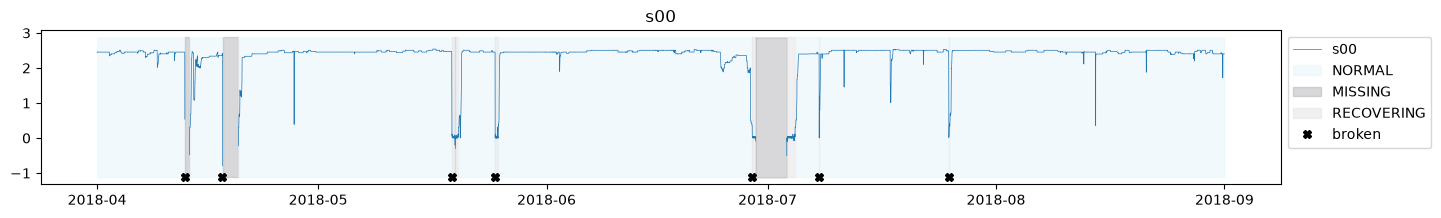

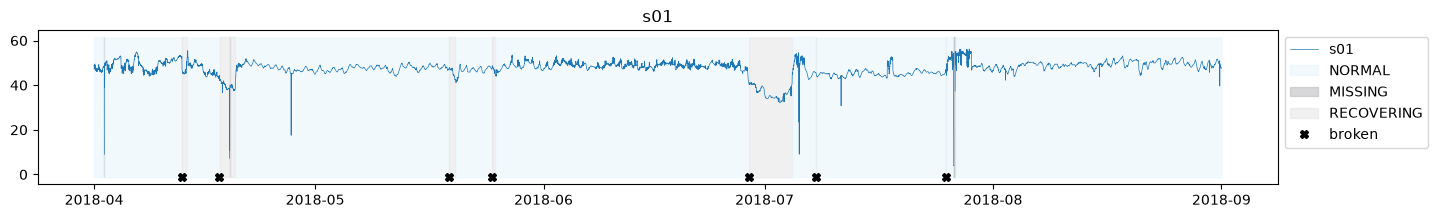

In [17]:
# s00とs01をプロット
import matplotlib.pyplot as plt

plot_anomaly_list(df, s_list=["s00", "s01"])

NORMAL：薄青色、RECOVERING：薄灰色、MISSING：灰色、BROKEN：×印

次にもう少し細かい粒度でプロットする。  
以下のコードで、全期間の始点と終点、およびBROKENとなった時点のインデックスのリストを作成する。

→`「データ全体を『故障サイクル』ごとに区切るための、区切り位置の時刻リストを作る」処理`

In [18]:
# BROKEN箇所のみのインデックス(timestamp)を取り出す
broken_indices = df[df["machine_status"] == "BROKEN"].index
indices = (
    pd.DatetimeIndex([df.index[0]])
    .append(broken_indices)
    .append(pd.DatetimeIndex([df.index[-1]]))
)

次に、インデックスを境界にデータフレームを分割し、それぞれをplot_anomaly_list()関数に渡す。  
これで、７つの故障点によって分割された8つのデータフレームそれぞれについてプロットされる。

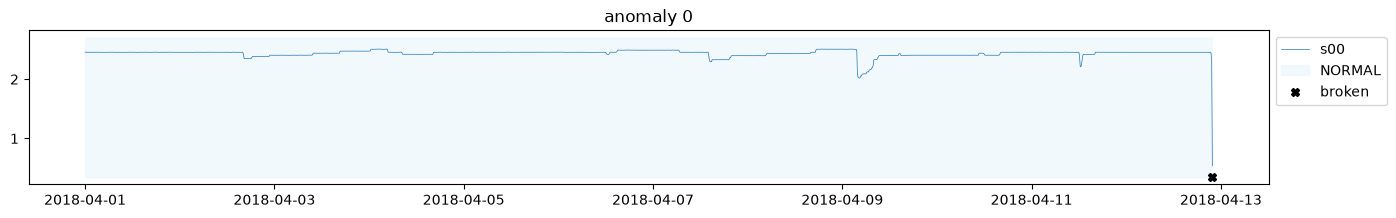

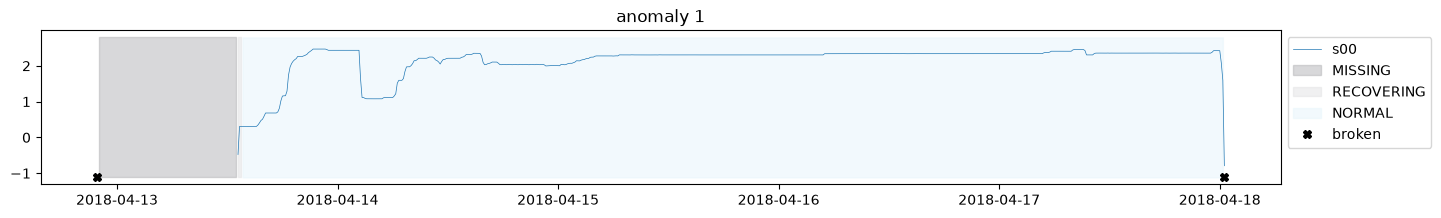

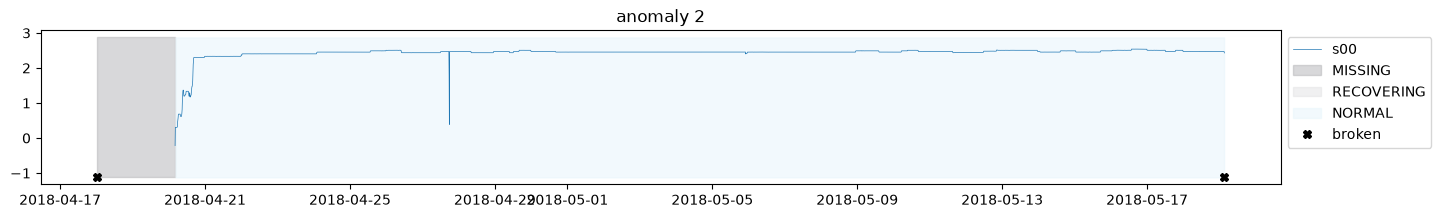

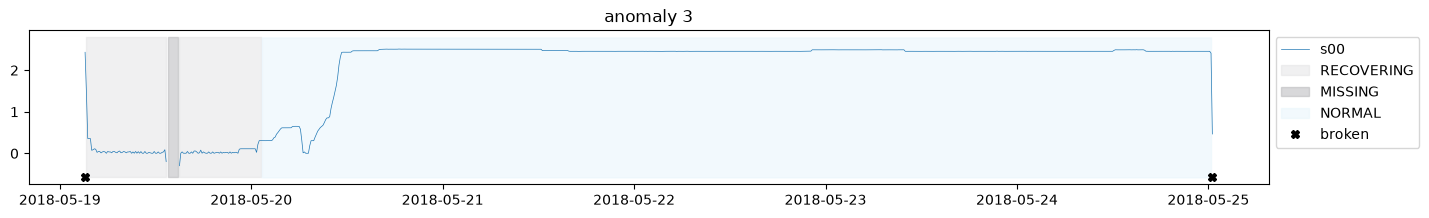

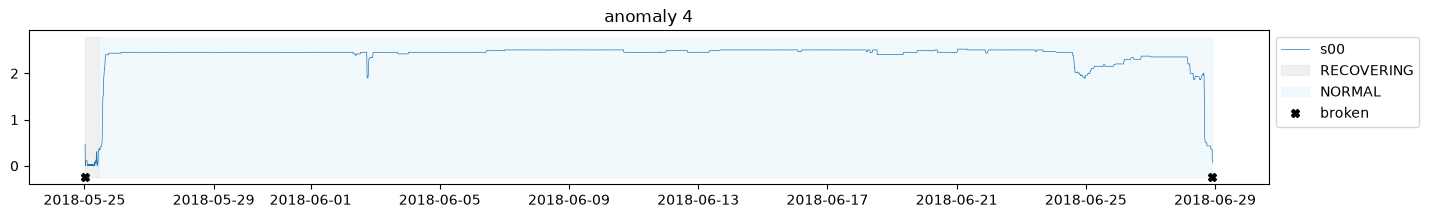

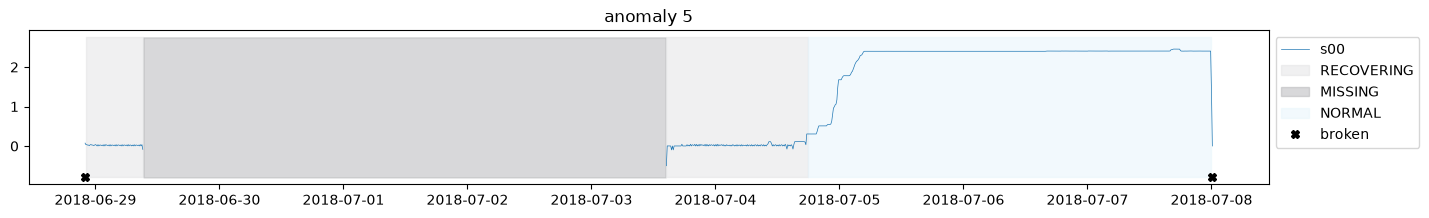

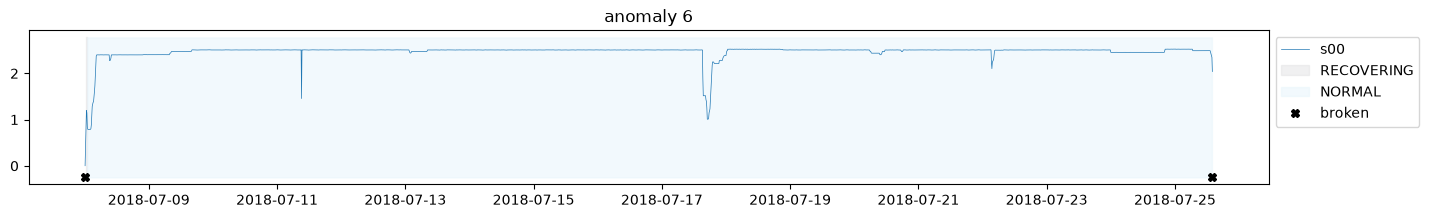

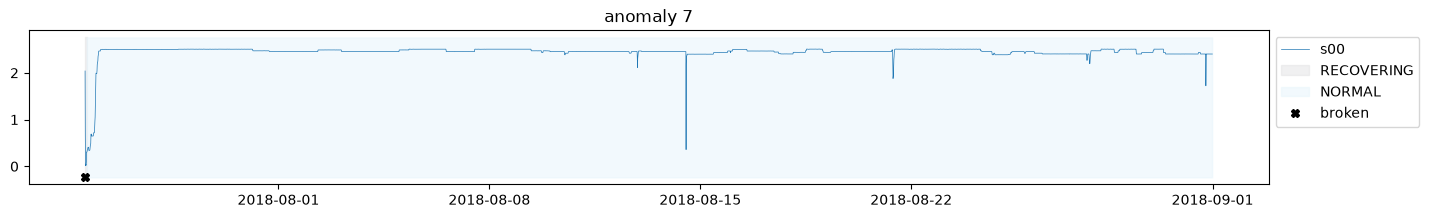

In [19]:
for i in range(len(indices) - 1):
    plot_anomaly_list(
        df.loc[indices[i]:indices[i+1]],
        s_list=["s00"],
        title=f"anomaly {i}"
    )

##### 故障時、センサー値が欠損していることがある。

故障直後、s00センサーはしばらく欠損することがあることが分かる。  
常に欠損するわけではなく、欠損しない場合、RECOVERINGの間は0に近い値をとる傾向がある。  
これは、欠損値の扱いをどうするかにおいて、重要な観察である。欠損値は主に除去するか、何かしらの値で補完するかの2択となる。欠損が完全にランダムであれば除去でよいが、法則性が見出せそうな場合、値補完が適切である。  
他のセンサー値も欠損している箇所は欠損前後で似たような値を取ることが多いので、一律で前回の値で補完すると、事前に補完できそう！

In [20]:
#前回の値で欠損値補完
df = df.bfill()

##### 修理後、センサー値が不安定

修理完了後、RECOVERINGからNORMALに遷移した後もしばらく(1日程度)センサー値が安定していないことが分かる。  
→修理後、安定するまで時間がかかる、ということ。  

この期間のデータをそのまま学習してしまうと、この期間を異常と判定してしまう恐れがあるため、学習から除いた方がよさそう！  
今回はs00を基に、NORMAL状態のうち、安定するまでの期間を新たにSTABILIZATION状態として定義することとする。  

以下、NORAMLラベルのうち、安定化期間をSTABILIZATIONラベルに変換する関数である。  
データ観察より、平均2.2以上、標準偏差0.05未満を安定化完了の基準として、それまではSTABILIZATION状態としている。

In [21]:
def add_stabilization_status(df):
    # RECOVERINGからNORMALに代わるポイント（=復旧完了の瞬間を見つける）
    # shift(1):1つ前の行を見る。
    # NORMAL且つ1つ前がRECOVERINGの行を抽出
    recovering_to_normal = (
        (df["machine_status"] == "NORMAL")
        & (df["machine_status"].shift(1) == "RECOVERING")
    )
    recovering_to_normal_index = df.index[recovering_to_normal]

    # NORMALから将来のx分間のs00のstdが初めて0.05未満且つmeanが2.2以上になるポイントを見つけ、
    # それまでをSTABILIZATIONフェーズとする。
    for i in range(len(recovering_to_normal_index)):
        idx = recovering_to_normal_index[i] # 復旧完了時刻
        print(idx)
        # 6時間の窓を1時間ずつスライドさせながら安定条件を満たす場所を探す、設計
        minutes = 0 # 現在の累計ずらし量
        add_minutes = 60 # 窓をずらす幅。1時間ずつ後ろへ動かす 
        window_size = 360 # 判定に使う窓の幅。6時間分のデータを見る
        # 探索の打ち切り位置
        # 最後の要素でないなら「次の切り替え点の時刻」、最後の要素なら「最終時刻」
        limit = (
            recovering_to_normal_index[i+1]
            if i != len(recovering_to_normal_index) - 1
            else df.index.max()
        )
        # 安定を探す
        while(True): # 回数を決めずに条件が満たされるまで回り続けるループ
            begin = idx + pd.Timedelta(minutes=minutes) # 時間の長さを表すオブジェクト
            end = idx + pd.Timedelta(minutes = minutes + window_size) # endとbeginの間は常に6時間
            std = df.loc[begin:end, "s00"].std()
            mean = df.loc[begin:end, "s00"].mean()
            if std < 0.05 and 2.2 <= mean:
                df.loc[idx:begin, "machine_status"] = "STABILIZATION"
                break
            minutes += add_minutes

            if limit < end:
                df.loc[idx:end, "machine_status"] = "STABILIZATION"
                break
    
    return df

「安定」を以下2つで定義
1. 標準偏差が小さい
2. 平均が十分高い

In [22]:
df = add_stabilization_status(df)

2018-04-13 13:40:00
2018-04-20 04:30:00
2018-05-20 01:20:00
2018-05-25 10:40:00
2018-07-04 18:00:00
2018-07-08 01:00:00
2018-07-25 15:20:00


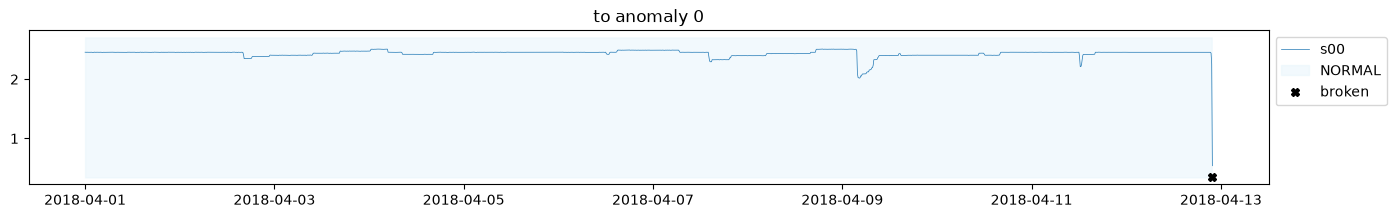

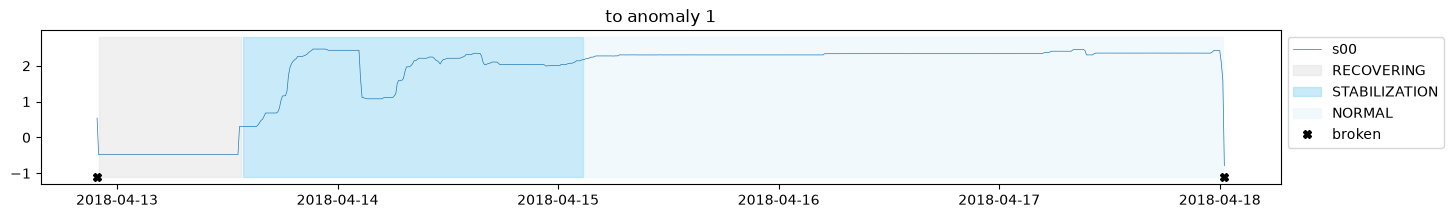

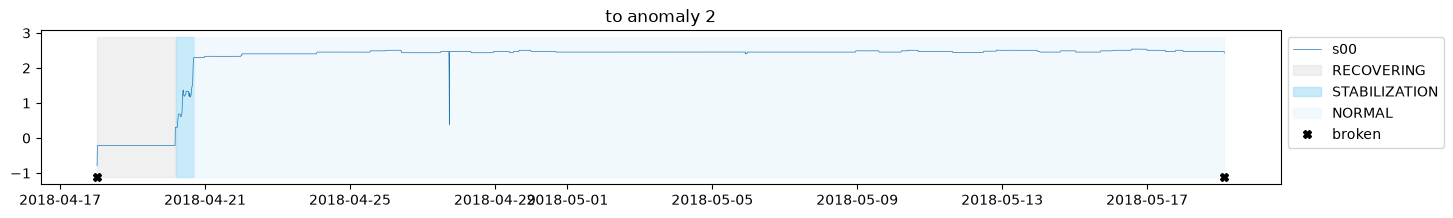

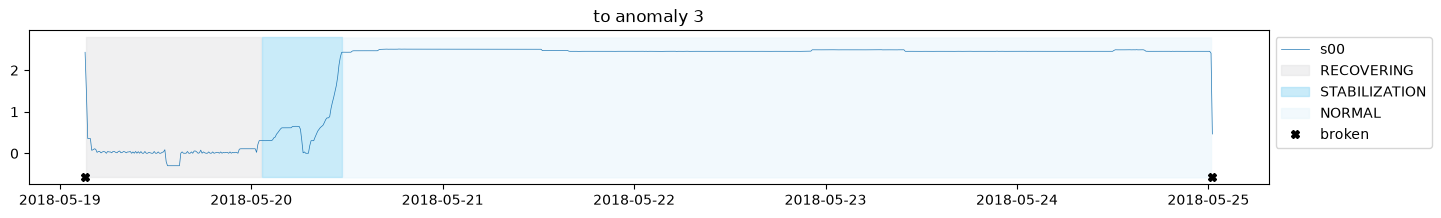

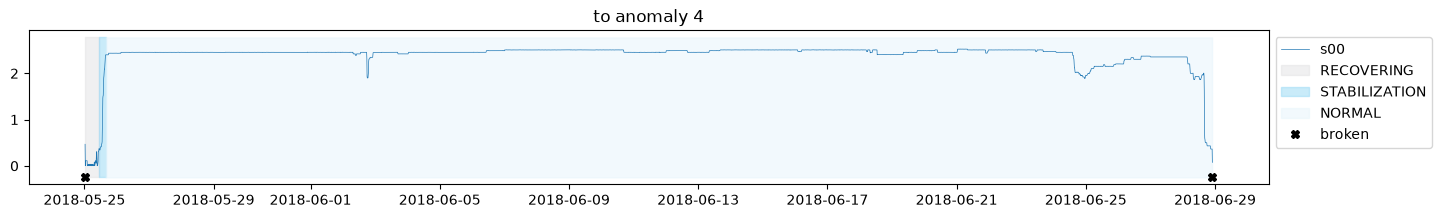

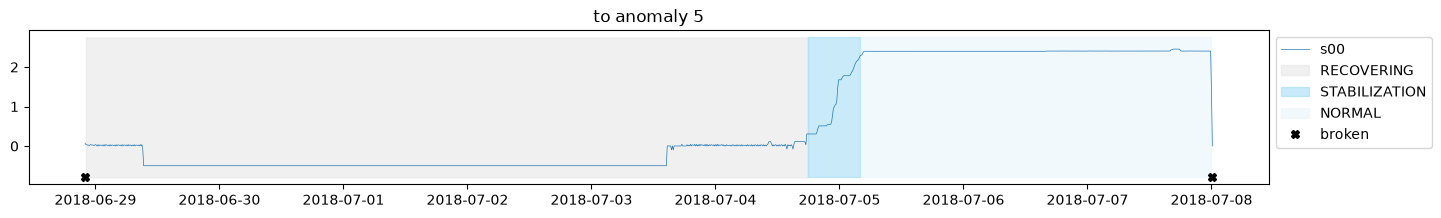

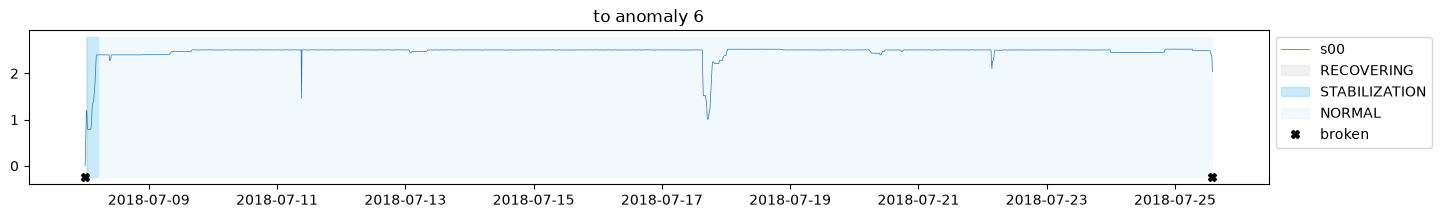

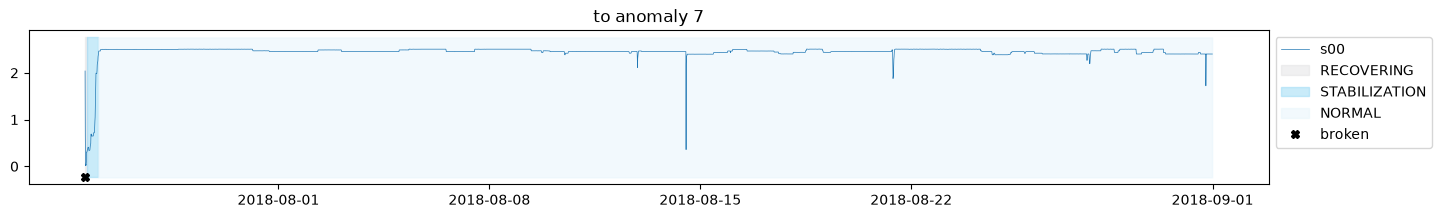

In [23]:
for i in range(len(indices) - 1):
    plot_anomaly_list(
        df.loc[indices[i]:indices[i+1]],
        s_list=["s00"],
        title=f"to anomaly {i}"
    )

これまでのデータ整形を次のように読み込み時に関数チェインで全実行しておくと扱い易い。  
そうしないと、同じdfでも、どのセルをこれまで実行したかによって、欠損値補完がされていたりされていなかったりと、状態が分かりにくくなる。 

In [24]:
df = (
    pd.read_csv(
        "sensor.csv",
        parse_dates=["timestamp"],
        index_col="timestamp"
    )
    .bfill()
    .ffill()
    .pipe(add_stabilization_status)
)

2018-04-13 13:40:00
2018-04-20 04:30:00
2018-05-20 01:20:00
2018-05-25 10:40:00
2018-07-04 18:00:00
2018-07-08 01:00:00
2018-07-25 15:20:00


### 特徴量エンジニアリング

時系列データで使える特徴量は主に次のようなものがある。

#### 一時点の値

データ観察時のデータフレームの各レコードのセンサー値をそのまま使うこと。  
例えば、あるセンサー値が10を切ると1時間以内に故障する可能性が高いことが分かっている場合に有用。

#### 過去時点の値(ラグ特徴量)

故障の予兆が発生しているかを判定するために、過去時点の特徴量を用いる＝`ラグ特徴量`  
10分前、30分前など、いくつかのバリエーションで時間間隔を作るとよい。  
以下の関数でラグ特徴量を生成する。 

In [25]:
# この関数は、渡されたdfの全列に対して処理を行う仕組みになっているので、渡す際に処理を施したい列を指定する必要がある。
# periods:何行分過去に遡るかを指定する（1行=10分前）
# shift()：値を指定した行だけ下にずらす
# bfill():先頭の欠損を後ろの値で埋める。
# 元のdfから特定の列(例：s001)を取り出して、periods行だけ値をずらして、先頭行の欠損は後ろの値で埋めて、
# renameで"s001"という列名を"lag(s001, periods)"に変更する、という動き。
def generate_lag_features(df, periods):
    return df.shift(periods=periods).bfill().rename(columns={col:f"lag({col}, {periods})" for col in df.columns})

In [26]:
# 上記関数の動作確認
# []→Series(1次元), [[]]→DataFrame(2次元)
tmp_df = df[["s00"]]
# concat():連結したいものを引数に渡す。axis=1:横方向に連結。
pd.concat([
    tmp_df,
    generate_lag_features(tmp_df[["s00"]], periods=1)
], axis=1).head()

,s00,"lag(s00, 1)"
timestamp,,
2018-04-01 00:00:00,2.454966,2.454966
2018-04-01 00:10:00,2.455064,2.454966
2018-04-01 00:20:00,2.452899,2.455064
2018-04-01 00:30:00,2.456441,2.452899
2018-04-01 00:40:00,2.453391,2.456441


#### 二時点間の相対的な増加・減少値（差分特徴量）

一時点の値と、ラグ特徴量を新たな特徴量としたもの。いくつかのバリエーションで時間間隔を作るとよい。  
以下が、差分特徴量の関数である。  

In [27]:
# diff():差分、現在の値から、指定した期間前の値を引く。
def generate_diff_features(df, periods):
    return df.diff(periods=periods).bfill().rename(columns={col:f"diff({col},{periods})" for col in df.columns})

1回目の故障が起こってから2回目の故障が起こるまでのs00の時間間隔10分の差分特徴量を生成してプロットしてみると...

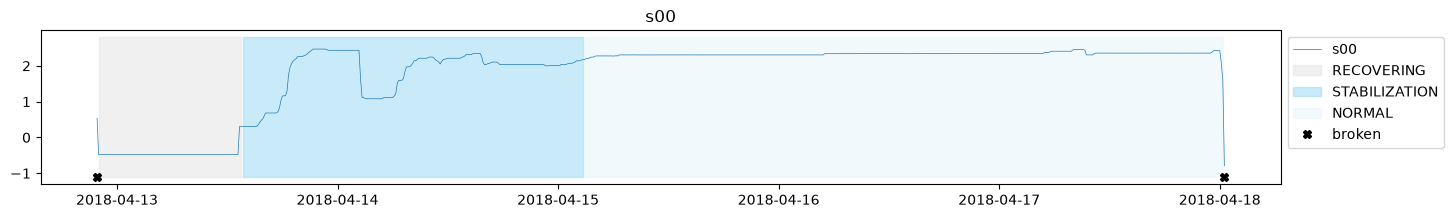

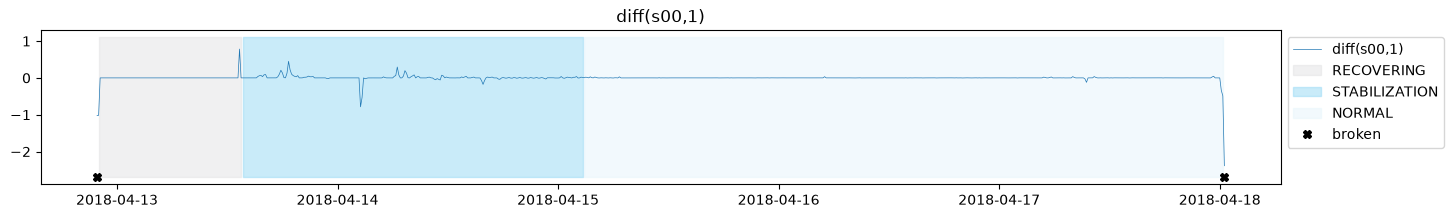

In [28]:
# loc[行, 列]
# broken_indices:ステータスがBROKENのみの日時データ
# broken_indicesの0行目（1回目の故障）から1行目(２回目の故障)までを行、s00とmachine_statusのみを列としたdfをtmp_dfに代入abs
tmp_df = df.loc[broken_indices[0]:broken_indices[1], ["s00", "machine_status"]]
plot_anomaly_list(
    pd.concat([
        tmp_df,
        generate_diff_features(tmp_df[["s00"]], periods=1)
    ], axis=1)
)
# ここでは、現在の値と１つ前の値とで毎回どの程度差が出ているかをdiff()で可視化している

差分特徴量diff(s00, 1)はs00が安定しているときには0付近を維持し、急激に増減しているときに対応してパルスのように値が増減していることが分かる。

#### 移動平均特徴量

一時点の値を単純に扱うと、ノイズによる局地的な上下動の影響を強く受けることになる。  
広い範囲でのトレンドを特徴量に反映させたい場合、`移動平均値`を使う。

In [29]:
# rolling:直近後ろn行を1つの窓としてまとめる。
# rolling().mean():移動平均。.std()は移動標準偏差。
def generate_moving_average_features(df, window):
    return df.rolling(window=window).mean().bfill().rename(columns={col:f"ma({col}, {window})" for col in df.columns})

1回目の故障が起こるまでのs06のウィンドウサイズ20(=200分)の移動平均特徴量は...

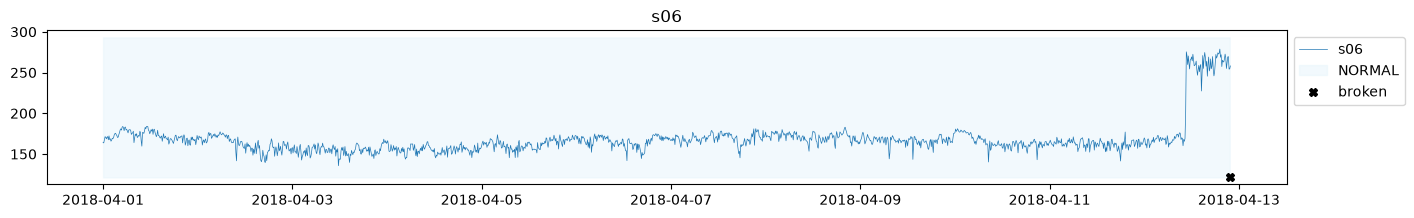

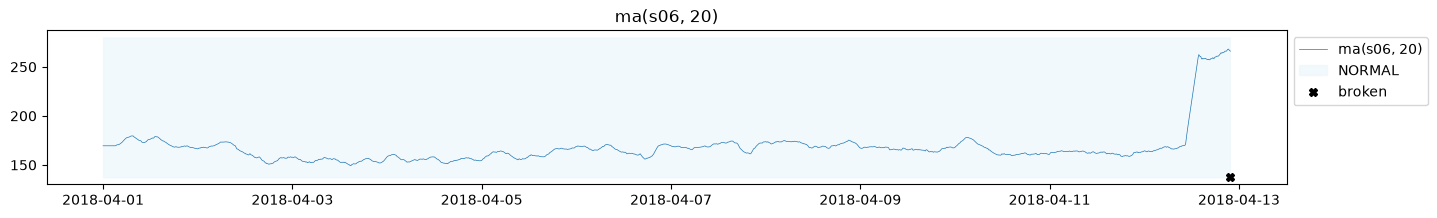

In [30]:
tmp_df = df.loc[:broken_indices[0], ["s06", "machine_status"]]
plot_anomaly_list(
    pd.concat([
        tmp_df,
        generate_moving_average_features(tmp_df[["s06"]], window=20)
    ], axis=1)
)

生成されたma(s06, 20)は局地的なノイズが除かれ、広範囲での傾向をとらえた特徴量になっていることが分かる。  

移動平均にすると、ウィンドウ内にパルス的な極端な値が1つでもあると、平均値がその影響を受けて大きく変わってしまう。これを避けるには、平均の代わりに中央値を用いる、ウィンドウ内の外れ値を事前に除去した平均にする、などの工夫が考えられる。

#### 移動平均ラグ特徴量

移動平均特徴量はラグ特徴量と組み合わせることが出来る。これにより、移動平均特徴量と同様に過去の値のトレンドを捉えることが出来る。  

移動平均ラグ特徴量は、ラグ特徴量生成関数と移動平均特徴量生成関数をパイプでつないで生成できる。  
以下では、1回目の故障が起こるまでのs06のピリオド10(=100分)のラグ特徴量と、ウィンドウ10の移動平均を取った特徴量の比較をする。  

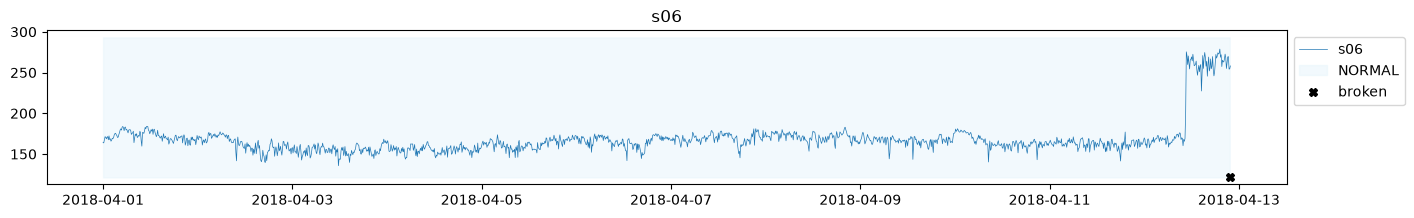

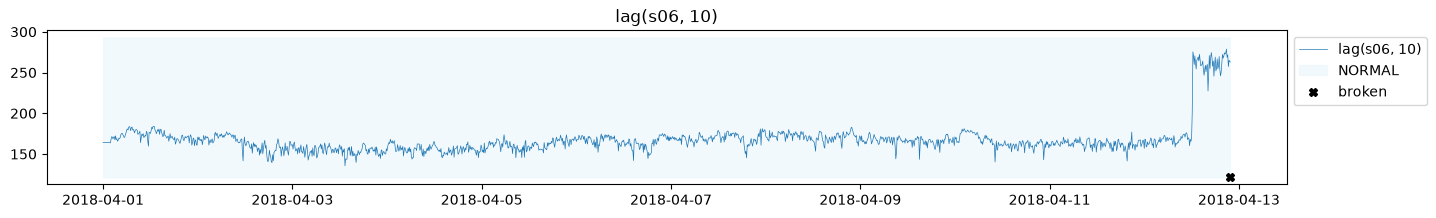

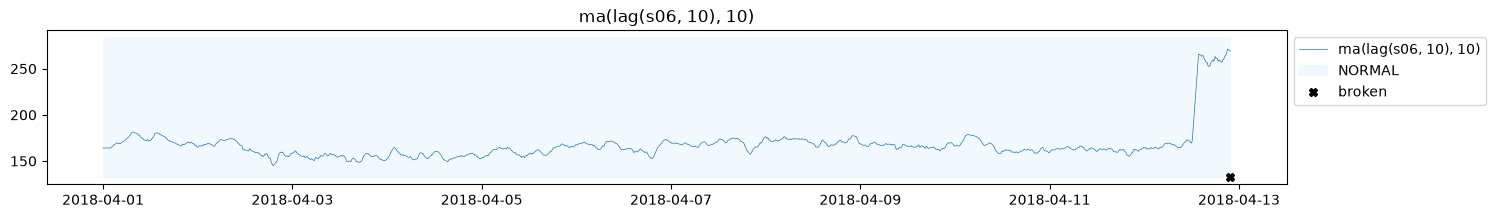

In [31]:
tmp_df = df.loc[:broken_indices[0], ["s06", "machine_status"]]
plot_anomaly_list(
    pd.concat([
        tmp_df, # 元のセンサーデータ
        generate_lag_features(tmp_df[["s06"]], periods=10), # ラグ特徴量
        generate_lag_features(tmp_df[["s06"]], periods=10).pipe(generate_moving_average_features, window=10)
    ], axis=1)
)

#### 移動平均差分特徴量

差分特徴量も移動平均と組み合わせた特徴量を生成できる。  
以下では、1回目の故障が起こるまでのs06のピリオド10(=100分)の差分特徴量と、ウィンドウ10の移動平均を取った特徴量の比較をする。  

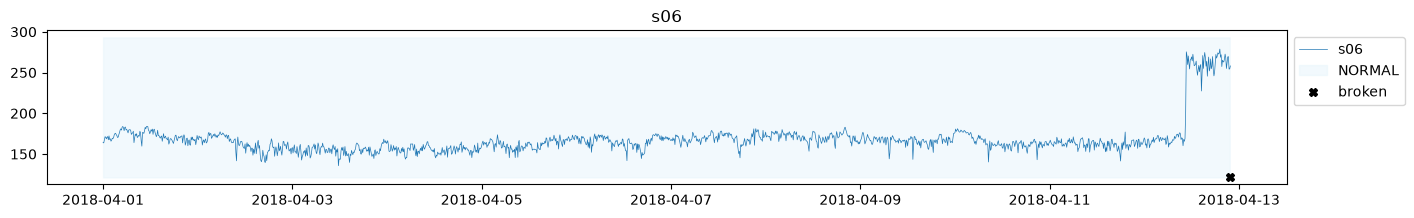

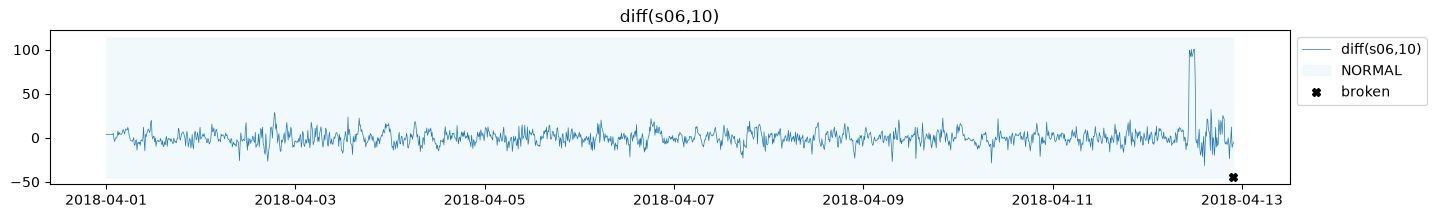

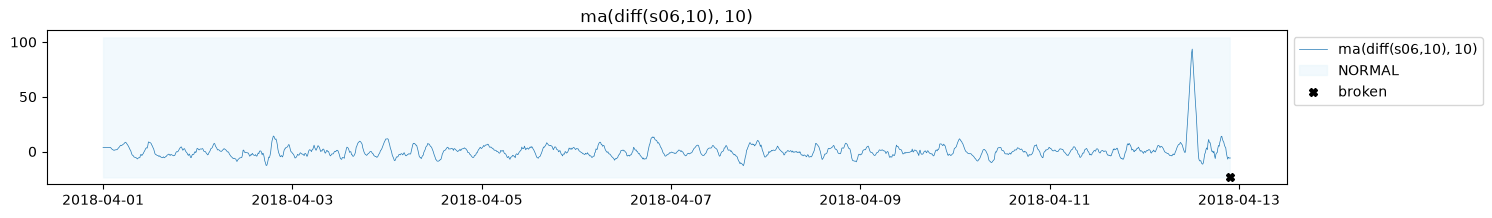

In [32]:
tmp_df = df.loc[:broken_indices[0], ["s06", "machine_status"]]
plot_anomaly_list(
    pd.concat([
        tmp_df, # 元のセンサーデータ
        generate_diff_features(tmp_df[["s06"]], periods=10), # 差分特徴量
        generate_diff_features(tmp_df[["s06"]], periods=10).pipe(generate_moving_average_features, window=10)
    ], axis=1)
)

#### 特徴量選択

これらの特徴量をピリオドやウィンドウのバリエーションを持たせて全通り作ると、特徴量の総数が非常に多くなり、学習に時間がかかってしまう。また、似たような特徴量も増えるので、無駄も多くなる。  
事前に似たような特徴量はなるべく削減するのが良い！

以下では、これまでの特徴量生成の実装を呼び出す関数を定義する。

In [33]:
# use_median：中央値かどうか(True or False)（False：中央値）
# use_lag：ラグかどうか(True or False)（False：差分）
def generate_features(df, period, window, use_median, use_lag):
    new_df = df.copy()
    if period != None:
        if use_lag:
            func = generate_lag_features
        else:
            func = generate_diff_features

        # df.pipe(関数, 引数...)：dfを指定の関数に渡す。
        new_df = new_df.pipe(func, periods=period)

    if window != None:
        if use_median:
            func = generate_moving_average_features
        else:
            func = generate_moving_average_features

        new_df = new_df.pipe(func, window=window)

    return new_df

次に、相関の高い特徴量を除いた上で特徴量を生成する関数を実装する。  

drop_highly_correlated_columns関数は生成した特徴量のうち、相関係数0.7を超える特徴量の組については、最初の特徴量だけを残すもの。

In [34]:
def drop_highly_correlated_columns(df):
    melted_corr = (
        df[df.describe().columns]
        .corr()
        .where(lambda df: np.triu(np.ones(df.shape), k=1).astype(bool))
        .reset_index()
        .melt(id_vars="index")
        .where(lambda df: df["index"] != df["variable"])
        .where(lambda df: df["value"] > 0.7)
        .dropna()
        .sort_values(["index", "variable"])
    )
    drop_columns = sorted(list(set(melted_corr["variable"])))

    return df.drop(columns=drop_columns)

● melted_corr：  
相関の高い特徴量のペア（重複なし）と相関係数が一目でわかるdfを作成  
・df[df.describe().columns]：  
describe()は数値列しか扱わないので、自然とmachine_status列を落として、数値列＝センサー列だけを残して、dfを作成。  

・.corr()：相関行列を作る  
→①対角線は必ず1.0、②AxBとBxAのように同じ組が２組出てくる  

・where(np.triu(np.ones(df.shape), k=1).astype(bool))：  
→np.ones：dfの同じ型の全て1の配列を作成  
→np.triu( , k=1)：対角線を含めずに右上三角部分を残す
→astype(bool)：1→True、0→Falseに変換  
→where()：Falseの場所をNaNにする。  

・.reset_index()：  
元の一番左の列をインデックスとして、更に0,1,2と連番で番号が振られる。  

・.melt(id_vars="index")：  
id_varsで指定した列はそのままで、その他の列を縦に積む  

・.where(lambda df: df["index"] != df["variable"])：  
行名と列名が異なるものがTrue、つまり、行名と列名が同じ行をNaNにする。（np.triuで対角線を含めない設定をしているので、実質不要）  

・.where(lambda df: df["value"] > 0.7)：  
valueが0.7を超えるものを残して、それ以外はNaN  

・.dropna().sort_values(["index", "variable"])  
NaNを削除して、並べ替え。  
→"value"と"variable"はmelt()で縦持ちにした時にpandasが自動で作成した列。  
"value"には値そのもの、"variable"には元の列名。

● drop_columns：  
重複を除いたvariable列の値を抽出(set())して、リスト化する。  
相関の高い特徴量ペアの片方を消すための「片方」に当たる要素を取り出している。

● return df.drop(columns=drop_columns)  
dfから指定の特徴量を削除  

In [35]:
from itertools import product
import numpy as np

In [36]:
# 「全センサーについて、特徴量のパラメータを総当たりで試して、使える列を集める」関数
#　2重ループ構造：外でセンサーを順番に取りだして、中でパラメータの組み合わせを試す。
def select_features(df: pd.DataFrame):
    # 試すパラメータの一覧
    periods = [None, 1, 3, 6, 12, 18]
    use_lags = [True, False]
    windows = [None, 1, 3, 6, 12, 18]
    use_medians = [True]

    # 結果を入れる入れ物
    result_df = df.copy()
    selected_feature_params = []
    # センサー列を順番に取りだす
    # filter(regex="")：列名を正規表現で絞り込むメソッド  
    # ^(先頭が)s(で)\d(数字1文字)\d(数字1文字) = つまり、「先頭s＋数字2桁で始まる列」
    for original_col in df.filter(regex=r"^s\d\d").columns:
        print(original_col)

        # パラメータ調整したセンサー列を溜める箱
        # for original_colの中にあることがポイント。 
        # 扱うセンサー列が変わるたびに、リスト内はリセットされる。
        new_dfs = []
        #パラメータを総当たりする 
        # product()：自動で全組み合わせを作成する。
        for period, window, use_lag in product(periods, windows, use_lags):
            # periodもwindowもNoneの場合 & priodがNoneでuse_lagの指定がある場合、その組み合わせは使わない（加工しないのと同じだから）
            # if~continueはifに該当すると、continueでforループに戻る
            if period is None and window is None:
                continue
            if period is None and use_lag:
                continue
            
            sensors_df = df[[original_col]]
            new_df = generate_features(
                sensors_df, period, window, use_median=True, use_lag=use_lag
            )
            new_dfs.append(new_df)
            # new_dfs：ifを通り抜けたパラメータの組み合わせで加工した"1種類"のセンサー列のリスト。
            # つまり、Aパターンで加工したs001, Bパターンのs0001,...みたいな

        # features_df：60パターンで加工した1つのセンサー列データを列方向に結合
        features_df = pd.concat(new_dfs, axis=1)
        print(features_df.shape)
        # 相関の高い特徴量を除去
        features_df = drop_highly_correlated_columns(features_df)
        print(features_df.shape)

        # 元データ(コピー)+加工センサー列dfの結合 
        result_df = pd.concat(
            [result_df, features_df], axis=1
        )
        print()

    print(f"selected: {result_df.columns}")
    return result_df, selected_feature_params

NORMALのレコードのみを抽出して、特徴量を生成する。 NORMALのレコードのみを抽出して、特徴量を生成する。  
これによって1020個ほどの特徴量を226個まで絞ることが出来た。

In [37]:
normal_df = df[df["machine_status"]=="NORMAL"].drop(columns=["machine_status"])
features_df, selected_feature_params = select_features(normal_df)

s00
(20049, 65)
(20049, 5)

s01
(20049, 65)
(20049, 6)

s02
(20049, 65)
(20049, 5)

s03
(20049, 65)
(20049, 5)

s04
(20049, 65)
(20049, 5)

s05
(20049, 65)
(20049, 5)

s06
(20049, 65)
(20049, 7)

s07
(20049, 65)
(20049, 6)

s08
(20049, 65)
(20049, 7)

s09
(20049, 65)
(20049, 7)

s10
(20049, 65)
(20049, 7)

s11
(20049, 65)
(20049, 7)

s12
(20049, 65)
(20049, 7)

s13
(20049, 65)
(20049, 7)

s14
(20049, 65)
(20049, 6)

s15
(20049, 65)
(20049, 6)

s16
(20049, 65)
(20049, 6)

s17
(20049, 65)
(20049, 6)

selected: Index(['s00', 's01', 's02', 's03', 's04', 's05', 's06', 's07', 's08', 's09',
       ...
       'ma(diff(s16,1), 3)', 'ma(diff(s16,1), 6)', 'ma(diff(s16,1), 12)',
       'ma(diff(s16,1), 18)', 'ma(s17, 1)', 'diff(s17,1)',
       'ma(diff(s17,1), 3)', 'ma(diff(s17,1), 6)', 'ma(diff(s17,1), 12)',
       'ma(diff(s17,1), 18)'],
      dtype='str', length=128)


異常検知では`正常だけを学習させることで、そこから外れたものを異常と呼ぶ`という考え方をする。  
異常データはデータ数が少ないため、少ないパターンしか学習できないし、分類モデルを作っても全部正常と答えるだけで正解率が跳ね上がる。  

## アルゴリズムの選定・評価方法の選定

### Isolation Forest

異常検知の代表的な手法の1つ。ランダムフォレストを用いた教師なし学習。ランダムに選択された特徴量の値分割を最終的に観測点が孤立するまで繰り返す。繰り返しの分割を機構造で表現した時、複数の木構造からなるフォレストを形成する。木構造の集合として見た時、特定の観測点について、ルートノードから孤立するまでの距離（深さ）が平均的に短い場合、その観測点は異常である可能性が高い、とみなす。より早いタイミング（より少ない条件）で孤立させられるということは、他の多数の観測点とは異なる傾向を持つ可能性が高いということを意味する。  

### Lacoxal Outlier Factor（局所外れ値因子法, LOF）

異常検知の代表的な手法の1つ。各観測点のk個の最近傍点を基にして計算された局所的な密度をその近傍軍の局所密度と比較した時、周囲と比較して密度が低い点を外れ値とみなす、という考え方。  

LOFは、「自分は近所と比べてどれだけスカスカ（＝櫃度が低い）か」の相対評価である。  

### アルゴリズムの比較  

Isolation Forestは、データからパラメータを学習し、ランダムフォレストのモデルを学習する。そのため、学習データでモデルを学習した後は、運用時には運用データのみを与えて異常検知予測を行うことが出来る。  
LOFは、パラメータの学習を行わないモデルフリーなアルゴリズム。そのため、常に予測時に与えたデータのみを使って異常検知を行う。運用時にどのようにデータを与えるかは適切に設計する必要がある。入力データを過去の蓄積データ全て、とした場合、データが蓄積すればするほど精緻な見地を期待できるかもしれないが、計算にかかる時間が増幅する。  
これらのトレードオフを考慮して、直近〇〇ヶ月分のデータ、のように期間を定めてデータを使用するといった折衷案が考えられる。  

## 機械学習モデルの学習・予測

### Isolation Forest


まず、パイプラインを作成する関数を実装する。  
これは、LOFとも共通して利用する。  

In [38]:
# 前処理パイプライン作成
# 引数：標準化させる列名のリスト  
def create_preprocessor(numeric_feature_names: list[str]):
    # steps：("名前". 処理)のタプル
    # 今回は標準化1つのため、Pipeline()を使わなくても「=StandardScaler()」で動く。
    # が、Pipelineでは、後で処理を追加しやすい。
    numeric_transformer = Pipeline(steps=[("scaler", StandardScaler())])
    # 指定した列に、処理を当てる装置
    preprocessor = ColumnTransformer(transformers=[("num", numeric_transformer, numeric_feature_names)])
    return preprocessor

# # 「前処理」と「モデル」を1本につなぐ関数  
def create_pipeline(anomaly_detector, numeric_feature_names: list[str]):
    pipeline = Pipeline([
        ("preprocessor", create_preprocessor(numeric_feature_names=numeric_feature_names)),
        ("anomaly_detector", anomaly_detector)
    ])
    return pipeline

preprocessor：数値特徴量に対してStandardScaler()で標準化  
anomaly_detector：異常検知モデルの適応  

次に、IsolationForestのインスタンスを指定。学習パラメータを与える。  

In [39]:
pipeline_isolationforest = create_pipeline(
    anomaly_detector=IsolationForest(random_state=1234),
    numeric_feature_names=features_df.columns.tolist()
)

作成したパイプラインに対してfit関数を実行する。  
これにより、predict関数やdecision_function関数を実行できるようになる。  

In [40]:
pipeline_isolationforest.fit(features_df)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('anomaly_detector', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](128,)","['s00','s01','s02',...,'ma(diff(s17,1), 6)','ma(diff(s17,1), 12)', 'ma(diff(s17,1), 18)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,128
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This 

次に予測を行う関数を実装する。

In [41]:
def predict(df, predicted_func, score_func):
    # 予測結果(1 or -1)を新しくpredicited列として入れる
    predictions_df = pd.DataFrame(
        predicted_func(df),
        index=df.index,
        columns=["predicted"]
    )
    # 予測値を新しくscore列として入れる
    scores_df = pd.DataFrame(
        score_func(df),
        index=df.index,
        columns=["score"]
    )
    # 予測とスコアのみのdfを作成
    result_df = (
        pd.DataFrame(
            index=pd.date_range(
                start=df.index.min(), 
                end=df.index.max(), 
                freq="10min") # 10分間隔のデータ
            )
        .join(predictions_df)
        .join(scores_df)
    )
    return result_df

In [42]:
predicted_isolationforest_df = predict(
    features_df,
    predicted_func = pipeline_isolationforest.predict,
    score_func = pipeline_isolationforest.decision_function
)
predicted_isolationforest_df

,predicted,score
2018-04-01 00:00:00,1.0,0.091712
2018-04-01 00:10:00,1.0,0.102135
2018-04-01 00:20:00,1.0,0.099553
2018-04-01 00:30:00,1.0,0.101124
2018-04-01 00:40:00,1.0,0.119135
...,...,...
2018-08-31 23:10:00,1.0,0.065188
2018-08-31 23:20:00,1.0,0.098460
2018-08-31 23:30:00,1.0,0.102771
2018-08-31 23:40:00,1.0,0.095773


異常検知の結果の可視化を行う関数の実装  
（ここでは長くなるため説明を省く）

In [43]:
ANOMALY_LABEL = -1
NORMAL_LABEL = 1

In [44]:
def _regard_sequential_anomaries_as_one_anomaly(predicted, interval = 0):
    predicted.name = "predicted"
    reset_predicted = predicted.reset_index()
    new_predicted = pd.Series(
        name="predicted", index=predicted.index, dtype="float64"
    )
    for i, row in reset_predicted.iterrows():
      if (
          row["predicted"] == -1 and
          -1 in reset_predicted.iloc[
              max(0, i - interval - 1):i
          ]["predicted"].tolist()
      ):
        new_predicted.iloc[i] = 1
      else:
        new_predicted.iloc[i] = row["predicted"]

    return new_predicted

def _rescaling(sr, min_v, max_v):
    sr = (sr - sr.min()) / (sr.max() - sr.min())
    sr = sr * (max_v - min_v) + min_v
    return sr

def plot_predicted_result(
    df: pd.DataFrame, original_df: pd.DataFrame,
    extra_df: Optional[pd.DataFrame] = None,
    sensor_id: Optional[str] = None,
    threshold: Optional[float] = None,
    title: Optional[str] = None,
    score_label: Optional[str] = None,
    extra_score_label: Optional[str] = None,
):
    df = (
        df.join(original_df["machine_status"])
    )
    if sensor_id:
        df = df.join(original_df[sensor_id])

    if threshold is None:
        threshold = df["score"].quantile(
            1 - 10/(24*60/10)  # 1日に10回程度
        )
    print(f"threshold: {threshold}")

    predicted = df["score"].apply(
        lambda x: -1 if x < threshold else 1
    ).pipe(
        _regard_sequential_anomaries_as_one_anomaly,
        interval=6,  # 1時間以内に再度起こった検知は同一検知と見なす
    )
    machine_status = df["machine_status"]
    score = df["score"]

    min_v = score.min()
    max_v = score.max()
    anomaly_y = min_v - (max_v - min_v) * 0.1
    normal_y = max_v + (max_v - min_v) * 0.1

    plt.figure(figsize=(16, 2))

    regions = detect_status_regions(df)

    # machine_status のプロット
    colors = {
        "NORMAL": "#e7f5fc",
        "RECOVERING": "#e2e3e4",
        "MISSING": "#b2b3b6",
        "STABILIZATION": "#95d8f5",
    }
    for region in regions:
        if region["status"] == "BROKEN":
            continue

        plt.fill_between(
            df.iloc[region["begin"]:region["end"]].index,
            anomaly_y,
            normal_y,
            color=colors[region["status"]],
            label=region["status"],
        )

    # センサーデータのプロット
    if sensor_id:
        sensor = df[sensor_id]
        sensor = _rescaling(df[sensor_id], score.min(), score.max())
        plt.plot(sensor.ffill(),
                 linewidth=0.5, label=sensor_id)

    # 予測スコアのプロット
    plt.plot(score.ffill(),
             linewidth=0.5, label=score_label or "prediction score")

    if extra_df is not None:
        # 予測スコア(追加分)のプロット
        extra_score = _rescaling(extra_df["score"], score.min(), score.max())
        plt.plot(
            extra_score.ffill(),
            linestyle="--", linewidth=1.5,
            label=extra_score_label or "prediction score (extra)",
            color="darkgray"
        )
    else:
        # 異常と予測した点のプロット
        predicted_as_anomaly = mask_and_other_is_nan(
            predicted,
            predicted == ANOMALY_LABEL,
            anomaly_y
        )
        plt.plot(
            predicted_as_anomaly, linestyle="none", marker="x",
            label="predicted as anomaly", color="black",
        )

        # 正常と予測した点のプロット
        predicted_as_normal = mask_and_other_is_nan(
            predicted,
            predicted == NORMAL_LABEL,
            normal_y,
        )
        plt.plot(
            predicted_as_normal, linestyle="none", marker=".",
            markersize=1, label="predicted as normal",
            color="darkgray",
        )

        # BROKEN ラベルが付与された点のプロット
        actually_broken = mask_and_other_is_nan(
            machine_status,
            machine_status == "BROKEN",
            anomaly_y,
        )
        plt.plot(
            actually_broken, linestyle="none", marker="X",
            label="broken", color="black",
        )

        n_predicted_as_anomaly = len(predicted_as_anomaly.dropna())
        days = (df.index.max() - df.index.min()).total_seconds() / (60 * 60 * 24)
        print(
            f"Predicted {n_predicted_as_anomaly} anomalies "
            f"({n_predicted_as_anomaly / days:.1f} anomalies / day)"
        )
        print(
            "Last 5 points predicted as anomaly is :"
        )
        for timedelta in (
            predicted.index.max() -
            predicted_as_anomaly.dropna().index.sort_values(ascending=False)[:5]
        ):
            print(f"{timedelta} before")

    plt.title(title or "Predicted Result")
    plt.legend()
    plt.legend(bbox_to_anchor=(1, 1), loc="upper left")
    plt.show()

In [45]:
def plot_predicted_results(
    result_df, original_df, sensor_id: Optional[str] = None,
    extra_result_df: Optional[pd.DataFrame] = None,
    threshold: Optional[float] = None,
    score_label: Optional[str] = None,
    extra_score_label: Optional[str] = None,
):
    broken_indices = df[df['machine_status'] == 'BROKEN'].index
    indices = (
        pd.DatetimeIndex([df.index[0]])
        .append(broken_indices)
        .append(pd.DatetimeIndex([df.index[-1]]))
    )
    for i in range(len(indices) - 1):
        sub_df = result_df.loc[indices[i]:indices[i+1]]
        if extra_result_df is not None:
            extra_sub_df = extra_result_df.loc[indices[i]:indices[i+1]]
        else:
            extra_sub_df = None

        if i == len(indices) - 1:
            title = "Predicted result to end"
        else:
            title = f"Predicted result to anomaly {i}"

        if len(sub_df.dropna()) > 0:
            plot_predicted_result(
                sub_df,
                original_df=original_df,
                sensor_id=sensor_id,
                extra_df=extra_sub_df,
                threshold=threshold,
                title=f"Predicted result for anomaly {i}",
                score_label=score_label,
                extra_score_label=extra_score_label,
            )

threshold: 0.08
Predicted 31 anomalies (2.6 anomalies / day)
Last 5 points predicted as anomaly is :
0 days 00:10:00 before
0 days 03:20:00 before
0 days 08:20:00 before
0 days 17:40:00 before
1 days 02:00:00 before


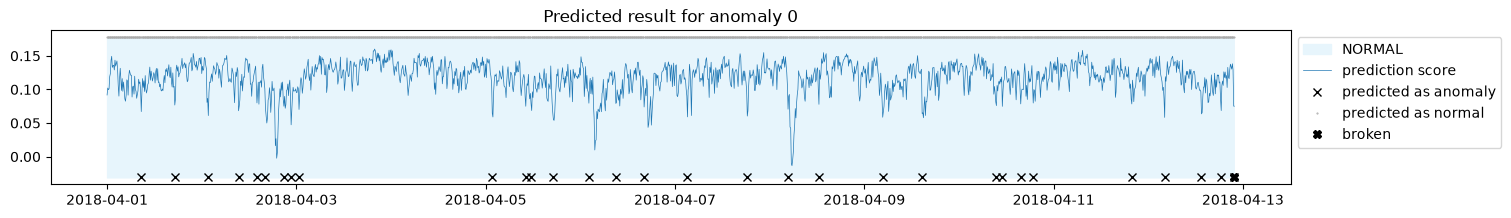

threshold: 0.08
Predicted 7 anomalies (1.4 anomalies / day)
Last 5 points predicted as anomaly is :
0 days 00:50:00 before
0 days 15:00:00 before
1 days 04:30:00 before
1 days 16:00:00 before
2 days 05:20:00 before


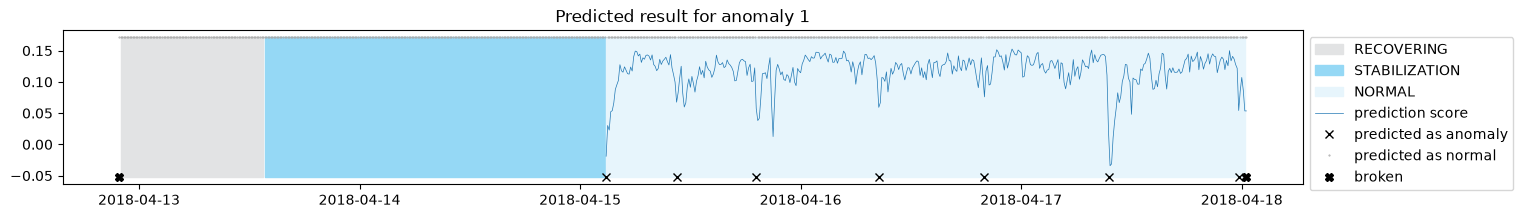

threshold: 0.08
Predicted 73 anomalies (2.3 anomalies / day)
Last 5 points predicted as anomaly is :
0 days 19:00:00 before
1 days 03:50:00 before
1 days 11:10:00 before
2 days 15:50:00 before
2 days 19:50:00 before


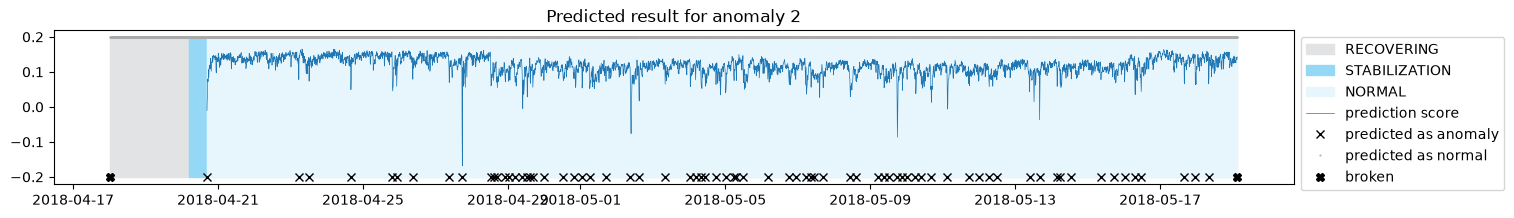

threshold: 0.08
Predicted 8 anomalies (1.4 anomalies / day)
Last 5 points predicted as anomaly is :
0 days 00:20:00 before
0 days 15:00:00 before
1 days 10:40:00 before
1 days 18:30:00 before
2 days 11:40:00 before


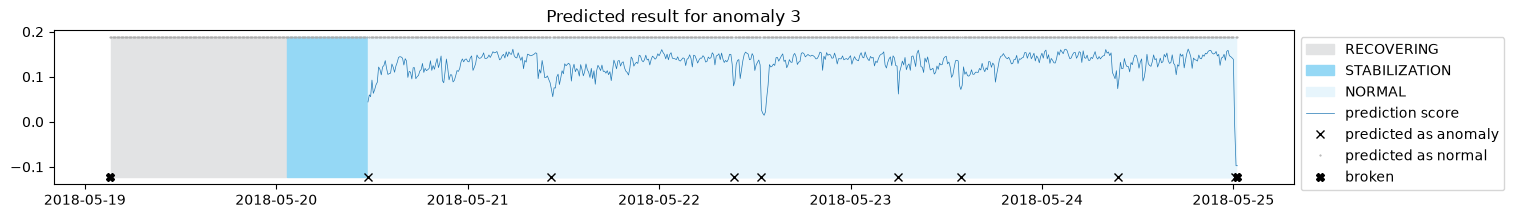

threshold: 0.08
Predicted 63 anomalies (1.8 anomalies / day)
Last 5 points predicted as anomaly is :
0 days 19:10:00 before
0 days 21:10:00 before
1 days 01:00:00 before
1 days 09:00:00 before
1 days 13:10:00 before


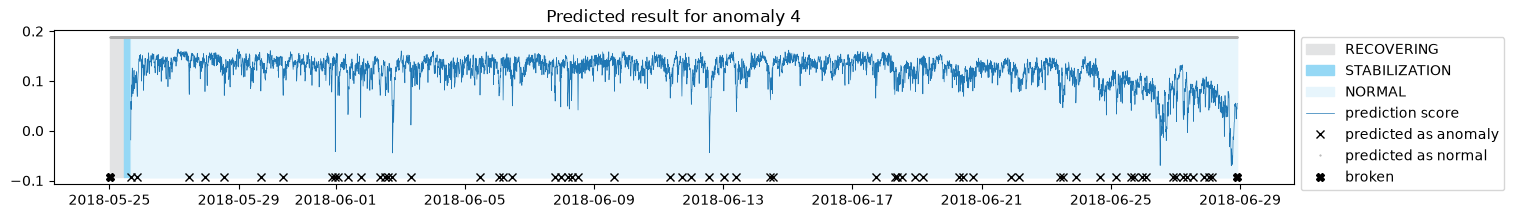

threshold: 0.08
Predicted 15 anomalies (1.7 anomalies / day)
Last 5 points predicted as anomaly is :
0 days 00:30:00 before
0 days 06:00:00 before
0 days 13:30:00 before
0 days 16:20:00 before
1 days 00:00:00 before


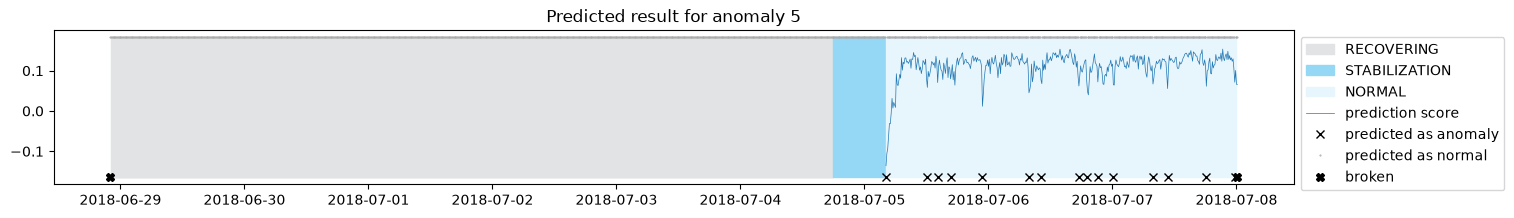

threshold: 0.08
Predicted 41 anomalies (2.3 anomalies / day)
Last 5 points predicted as anomaly is :
0 days 00:20:00 before
0 days 08:40:00 before
0 days 13:40:00 before
0 days 15:30:00 before
1 days 07:20:00 before


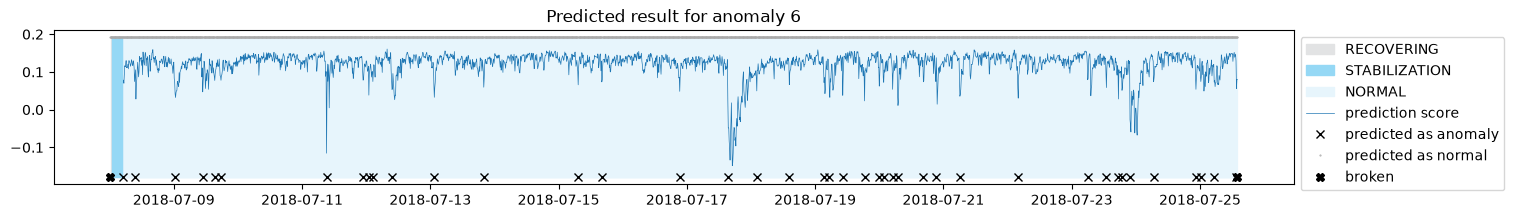

threshold: 0.08
Predicted 135 anomalies (3.6 anomalies / day)
Last 5 points predicted as anomaly is :
0 days 16:10:00 before
1 days 01:30:00 before
1 days 04:00:00 before
1 days 08:40:00 before
1 days 14:20:00 before


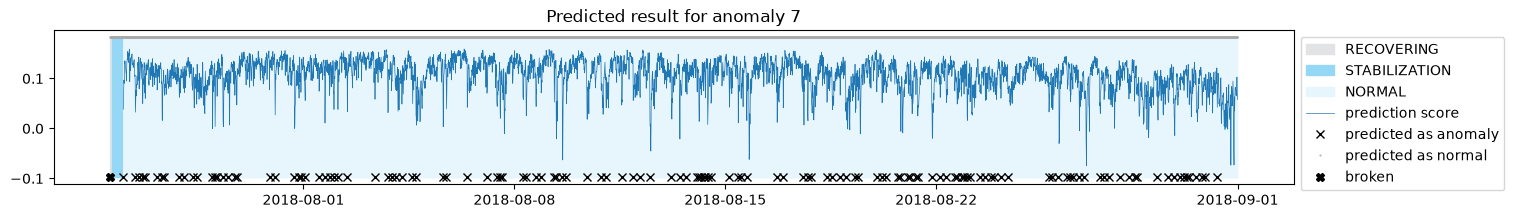

In [46]:
plot_predicted_results(
    predicted_isolationforest_df,
    original_df = df,
    threshold = 0.08 # 予測スコアの異常と正常の閾値となる値を設定
)

### Local Outolier Factor

Isolation Forest同様、パイプラインを作成する。

In [47]:
from sklearn.neighbors import LocalOutlierFactor

pipeline_lof = create_pipeline(
    anomaly_detector = LocalOutlierFactor(n_neighbors=20),
    numeric_feature_names = features_df.columns.tolist()
)

Isolation Forestではこの後fitを実行していたが、LOFでは。パラメータを学習しないため、fit_predictを実行する。  

predicted_funcにfit_predictを指定する。  
score_funcには、fit_predict済みのestimator(StandardScaler()やLocalOutlierFactor()などfitできるもの)のインスタンス(estimatorを実物として扱っているもの)に対して参照できるnegative_outlier_factor_を指定する。  
これはdecision_functionのようなものだが、メソッドではなくプロパティ値(メソッド：()を付けて呼ぶ、プロパティ値：()を付けずに参照するだけ)である点に注意。predictに与える際、インターフェースを揃えるため、ラムダ式を使って関数として渡す。

Isolation Forestの場合・・・  
pipeline.fit(df) - 学習  
pipeline.predict(df) - 判定  ←メソッド  
pipeline.decision_function(df) - スコア  ←メソッド  
→ どちらもfunc(df)の形で呼べるので、predictにそのまま渡せる。  

LOFの場合・・・  
上記、decision_functionに相当するものが、プロパティ値(属性)として置かれている。これは、関数ではないのでscore_func(df)の形で呼べない。  
→解決策：ラムダ式で包むことで、「dfを受け取って、その属性を返す関数」を作る。

In [48]:
predicted_lof_df = predict(
    features_df,
    predicted_func = pipeline_lof.fit_predict,
    # sklearnで末尾に_があるものは、「学習した後にできるもの」という決まり
    score_func = lambda x: pipeline_lof[1].negative_outlier_factor_
)
predicted_lof_df

,predicted,score
2018-04-01 00:00:00,1.0,-1.286911
2018-04-01 00:10:00,1.0,-1.264055
2018-04-01 00:20:00,1.0,-1.228518
2018-04-01 00:30:00,1.0,-1.174832
2018-04-01 00:40:00,1.0,-1.206282
...,...,...
2018-08-31 23:10:00,1.0,-1.419396
2018-08-31 23:20:00,1.0,-1.369240
2018-08-31 23:30:00,1.0,-1.264199
2018-08-31 23:40:00,1.0,-1.388972


## 機械学習モデルの評価

### ①でたらめでないことの確認

２つのアルゴリズムを比較することで、でたらめな予測をしているかどうかを確かめる。もし両者が同じような傾向を持っている場合、少なくともでたらめな予測をしているわけではなく、何かしらデータから特徴を抽出した上で予測をしていることが分かる。  

プロット関数を使って１つ目の異常が起こる直前１日分について、予測スコアの比較をする。  

threshold: -1.0548233684705286


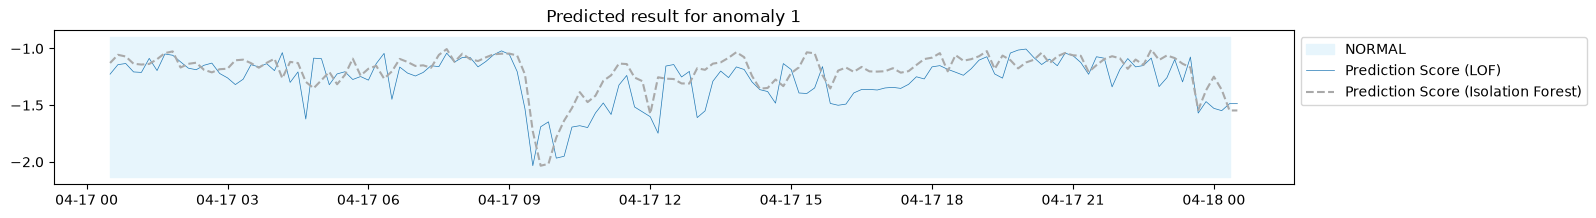

In [49]:
end = broken_indices[1]
begin = end - pd.Timedelta(days=1)

plot_predicted_results(
    predicted_lof_df[begin:end],
    extra_result_df=predicted_isolationforest_df[begin:end],
    original_df = df,
    score_label = "Prediction Score (LOF)",
    extra_score_label = "Prediction Score (Isolation Forest)"
)

両者の予測結果の傾向が大局的には一致していることが分かる。

### ②評価にはドメイン知識が必要

両者が全くでたらめに予測しているわけではなないことが分かったが、この予兆が、  
・その後の故障と結びつくものなのか  
・別の故障の予兆が表れているのか  
・故障とは関係のない何かの原因に起因するものなのか  
・ノイズを拾っているだけか  
など、何もわからない状態。  

今回、故障予兆ラベル（教師ラベル）がないため、どれくらい正確かの評価が出来ない。  

↓  

そのため、ドメイン知識を持つ有識者に確認を取る必要がある。  
その際に、`予測結果`と`予測の根拠となる特徴量`を示すと相手も判断しやすい。

### ③予測根拠となる特徴量の提示

予測根拠の提示手法は様々ある。  

次の関数は、各特徴量が予測スコアにどの程度影響を及ぼすかを計算するもの。  
`特徴量をランダム値にした時のスコアを計算し、元のスコアとの差の100個分の平均をその特徴の影響度`と定義している。  
（簡単に言うと、特定の特徴量だけをでたらめな値に置き換えてみて、それでスコアが大きく改善すれば、その特徴量が異常の原因だった、と特定するもの）  
※dfを入力としたscore_funcがあることを前提としているため、LOFには適応できない。

In [53]:
# df：調べたい１行のdf  
# original_df：元データ。ランダム値の範囲を決めるために使用  
# feature_score：ランダム値の範囲を取る列名  
def calc_contribution_score(df, original_df, feature_name, score_func):
    score = score_func(df) # 元のスコアを計算
    #　ランダム値の範囲
    u_limit = original_df[feature_name].max()
    l_limit = original_df[feature_name].min()

    assert len(df)==1 # assert 条件：条件に当てはまらなければ、処理を停止する。

    result_df = pd.DataFrame(index=df.describe().columns.tolist())
    new_scores = []
    # 特徴量ごとのループ
    for col in df.describe().columns:
        u_limit = original_df[col].max()       
        l_limit = original_df[col].min()
        # np.random.uniform():指定した範囲の中で一様乱数を100個作る。
        random_values = np.random.uniform(l_limit, u_limit_, 100)
        # [df]*100:同じdfが100個入ったリストを生成。
        # ignore_index=True：インデックスを0~99に振り直す。
        new_df = pd.concat([df] * 100, ignore_index=True)
        new_df[col] = random_values
        new_scores.append(score_func(new_df).mean())

    result_df["score"] = new_scores - score
    result_df = result_df.sort_values("score")
    display(result_df.head())
    display(result_df.tail())

In [56]:
def calc_contribution_score(df, original_df, score_func, n_samples=100, random_state=None):
    score = score_func(df)
    assert len(df) == 1, f"1行のはずが {len(df)} 行あります"

    gen = np.random.default_rng(random_state)
    result_df = pd.DataFrame(index=df.describe().columns.tolist())
    new_scores = []
    for col in df.describe().columns:
        u_limit = original_df[col].max()
        l_limit = original_df[col].min()
        random_values = gen.uniform(l_limit, u_limit, n_samples)
        new_df = pd.concat([df] * n_samples, ignore_index=True)
        new_df[col] = random_values
        new_scores.append(score_func(new_df).mean())

    result_df["score"] = new_scores - score
    return result_df.sort_values("score")

Isolation Forestが1回目の故障が発生するまでで最低のスコアを出した時点について、関数を実行し、影響度の大きい特徴量を列挙する。  

In [58]:
for broken_index in broken_indices:
    idx = predicted_lof_df.loc[
        predicted_lof_df.index < broken_index,
        "score"
    ].idxmin()
    display(predicted_isolationforest_df.loc[[idx]])

    res = calc_contribution_score(
        df=features_df.loc[[idx]],
        original_df=features_df,
        score_func=pipeline_isolationforest.decision_function,
        random_state=1234,
    )
    display(res.head())
    display(res.tail())

,predicted,score
2018-04-02 09:30:00,1.0,0.074963


,score
"ma(s09, 1)",-0.014117
"ma(diff(s11,1), 12)",-0.013146
"ma(diff(s04,1), 3)",-0.012376
"ma(s15, 1)",-0.011099
s13,-0.010326


,score
"ma(diff(s01,1), 12)",0.001189
"ma(diff(s03,1), 12)",0.001479
"ma(s03, 1)",0.003289
"diff(s01,1)",0.006741
"ma(diff(s01,1), 3)",0.007840


,predicted,score
2018-04-02 09:30:00,1.0,0.074963


,score
"ma(s09, 1)",-0.014117
"ma(diff(s11,1), 12)",-0.013146
"ma(diff(s04,1), 3)",-0.012376
"ma(s15, 1)",-0.011099
s13,-0.010326


,score
"ma(diff(s01,1), 12)",0.001189
"ma(diff(s03,1), 12)",0.001479
"ma(s03, 1)",0.003289
"diff(s01,1)",0.006741
"ma(diff(s01,1), 3)",0.007840


... (11 outputs left out)

,score
"ma(s16, 1)",0.004520
"ma(diff(s10,3), 3)",0.004872
"ma(diff(s17,1), 3)",0.005866
"ma(diff(s17,1), 6)",0.006485
"diff(s17,1)",0.006951


,predicted,score
2018-05-25 15:50:00,-1.0,-0.018448


,score
"ma(s00, 1)",-0.011949
"ma(diff(s04,1), 3)",-0.010578
"ma(diff(s09,1), 12)",-0.009874
"ma(diff(s01,1), 3)",-0.009554
s15,-0.009075


,score
"ma(s16, 1)",0.004520
"ma(diff(s10,3), 3)",0.004872
"ma(diff(s17,1), 3)",0.005866
"ma(diff(s17,1), 6)",0.006485
"diff(s17,1)",0.006951


この結果から最も影響が大きい特徴量が特定できる。  

予測の根拠となる特徴量を特定して、分析結果としてまとめて顧客に報告した後、うまくいけば、予測結果が実際に故障の予兆なのかどうかの切り分けが出来る可能性が見えてくる。  
そうすれば、予兆のラベルを付与出来て、教師あり学習として解くことで、より精緻な予測のできるモデルを構築することが期待できる。　　